In [2]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn streamlit mlflow joblib

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "CustomerID": range(1, n+1),
    "Age": np.random.randint(18, 70, n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Tenure": np.random.randint(1, 72, n),
    "MonthlyCharges": np.random.uniform(20, 150, n),
    "TotalCharges": np.random.uniform(100, 8000, n),
    "Contract": np.random.choice(
        ["Monthly", "Yearly", "Two Year"], n
    ),
    "InternetService": np.random.choice(
        ["DSL", "Fiber", "No"], n
    ),
    "SupportCalls": np.random.randint(0, 10, n)
})

df["Churn"] = (
    (df["SupportCalls"] > 6) |
    ((df["Contract"] == "Monthly") & (df["Tenure"] < 12))
).astype(int)

df.to_csv("outputs/raw_customer_data.csv", index=False)

df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,Contract,InternetService,SupportCalls,Churn
0,1,56,Male,21,41.978031,6128.885456,Two Year,No,9,1
1,2,69,Female,69,65.734651,6437.768516,Yearly,No,9,1
2,3,46,Female,48,119.017864,3142.338372,Yearly,Fiber,3,0
3,4,32,Male,20,85.920715,3401.283573,Two Year,No,0,0
4,5,60,Female,67,102.927244,451.621410,Two Year,No,0,0


In [5]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

df["Age"] = df["Age"].clip(18, 100)
df["MonthlyCharges"] = df["MonthlyCharges"].clip(lower=0)
df["TotalCharges"] = df["TotalCharges"].clip(lower=0)

assert df["CustomerID"].is_unique
assert df["Churn"].isin([0, 1]).all()
assert df["Age"].between(18, 100).all()

print("Data validation successful!")
print("Dataset shape:", df.shape)

df.to_csv("outputs/cleaned_customer_data.csv", index=False)

Missing values before cleaning:
CustomerID         0
Age                0
Gender             0
Tenure             0
MonthlyCharges     0
TotalCharges       0
Contract           0
InternetService    0
SupportCalls       0
Churn              0
dtype: int64
Data validation successful!
Dataset shape: (2000, 10)


        CustomerID          Age       Tenure  MonthlyCharges  TotalCharges  \
count  2000.000000  2000.000000  2000.000000     2000.000000   2000.000000   
mean   1000.500000    43.805500    36.641500       83.765634   4103.972888   
std     577.494589    14.929203    20.219579       37.848918   2261.758980   
min       1.000000    18.000000     1.000000       20.024249    110.017808   
25%     500.750000    31.000000    19.000000       50.788745   2218.570308   
50%    1000.500000    44.000000    37.000000       83.409050   4148.292843   
75%    1500.250000    56.000000    54.000000      116.498330   6019.055022   
max    2000.000000    69.000000    71.000000      149.876435   7998.809031   

       SupportCalls        Churn  
count   2000.000000  2000.000000  
mean       4.419000     0.311000  
std        2.876035     0.463019  
min        0.000000     0.000000  
25%        2.000000     0.000000  
50%        4.000000     0.000000  
75%        7.000000     1.000000  
max        9.0000

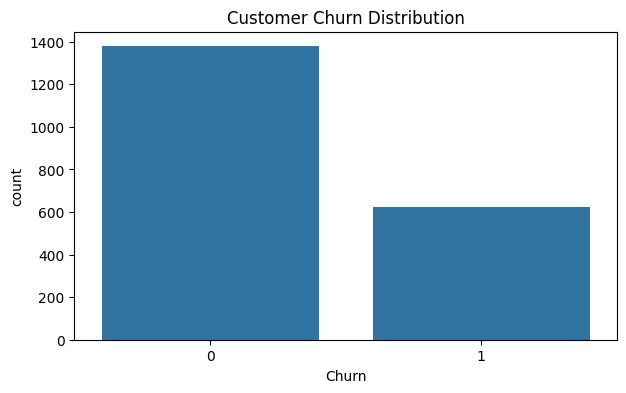

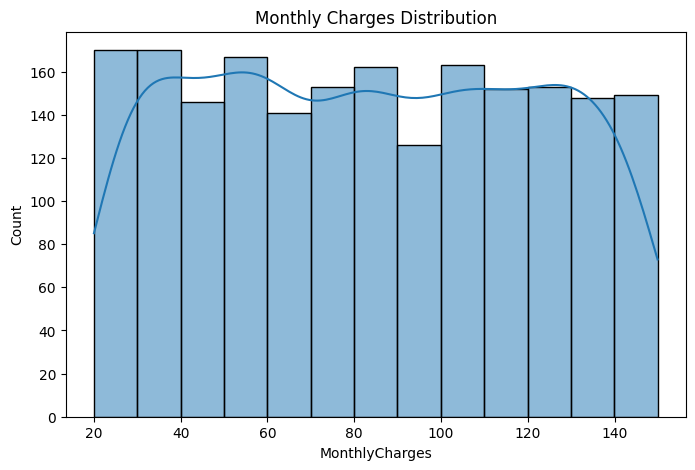

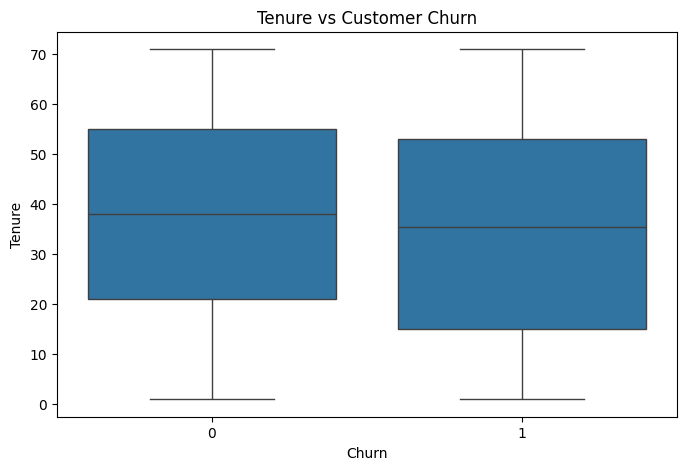

In [6]:
print(df.describe())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["MonthlyCharges"], kde=True)
plt.title("Monthly Charges Distribution")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="Tenure")
plt.title("Tenure vs Customer Churn")
plt.show()

In [7]:
df["AverageMonthlyValue"] = (
    df["TotalCharges"] / df["Tenure"].replace(0, 1)
)

df["CustomerSegment"] = pd.cut(
    df["Tenure"],
    bins=[0, 12, 36, 72],
    labels=["New", "Regular", "Loyal"]
)

df["HighSupportCustomer"] = (
    df["SupportCalls"] > 5
).astype(int)

df.to_csv("outputs/featured_customer_data.csv", index=False)

df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,TotalCharges,Contract,InternetService,SupportCalls,Churn,AverageMonthlyValue,CustomerSegment,HighSupportCustomer
0,1,56,Male,21,41.978031,6128.885456,Two Year,No,9,1,291.851688,Regular,1
1,2,69,Female,69,65.734651,6437.768516,Yearly,No,9,1,93.300993,Loyal,1
2,3,46,Female,48,119.017864,3142.338372,Yearly,Fiber,3,0,65.465383,Loyal,0
3,4,32,Male,20,85.920715,3401.283573,Two Year,No,0,0,170.064179,Regular,0
4,5,60,Female,67,102.927244,451.621410,Two Year,No,0,0,6.740618,Loyal,0


In [8]:
X = df.drop(
    columns=["Churn", "CustomerID"]
)

y = df["Churn"]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Reusable preprocessing pipeline created!")


Reusable preprocessing pipeline created!


In [9]:
model_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_pipeline.fit(X_train, y_train)

predictions = model_pipeline.predict(X_test)
probabilities = model_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, probabilities))
print(classification_report(y_test, predictions))

Accuracy: 1.0
ROC-AUC: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       276
           1       1.00      1.00      1.00       124

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



In [13]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, roc_auc_score

# Use SQLite instead of file-based tracking
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

# Create experiment
mlflow.set_experiment("Customer_Churn_Analytics")

# Track experiment
with mlflow.start_run():

    mlflow.log_param("model", "RandomForest")
    mlflow.log_param("n_estimators", 150)
    mlflow.log_param("test_size", 0.2)

    accuracy = accuracy_score(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("roc_auc", auc)

    print("Accuracy:", accuracy)
    print("ROC-AUC:", auc)

print("MLflow Experiment Tracking Successful!")

Accuracy: 1.0
ROC-AUC: 1.0
MLflow Experiment Tracking Successful!


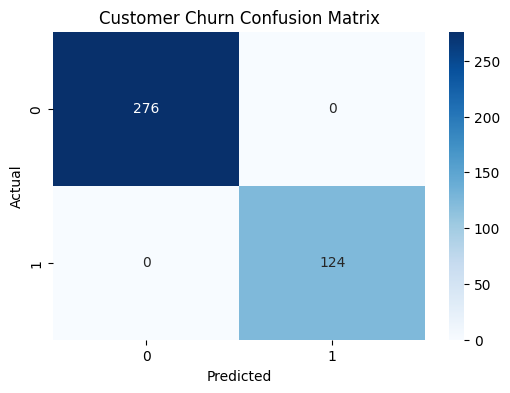

In [14]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn Confusion Matrix")
plt.show()

In [15]:
joblib.dump(
    model_pipeline,
    "outputs/customer_churn_model.pkl"
)

X_test_processed = model_pipeline.named_steps[
    "preprocessing"
].transform(X_test)

import scipy.sparse

if scipy.sparse.issparse(X_test_processed):
    X_test_processed = X_test_processed.toarray()

pd.DataFrame(X_test_processed).to_csv(
    "outputs/ml_ready_test_data.csv",
    index=False
)

print("Model and ML-ready dataset saved!")

Model and ML-ready dataset saved!


In [16]:
import shutil

shutil.make_archive(
    "Customer_Churn_Capstone",
    "zip",
    "outputs"
)

from google.colab import files
files.download("Customer_Churn_Capstone.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>